# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
from aitlas.datasets import HRSIDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

In [9]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/HRSID/JPEGImages/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/HRSID/annotations/train_test2017.json",
}
dataset = HRSIDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 5604


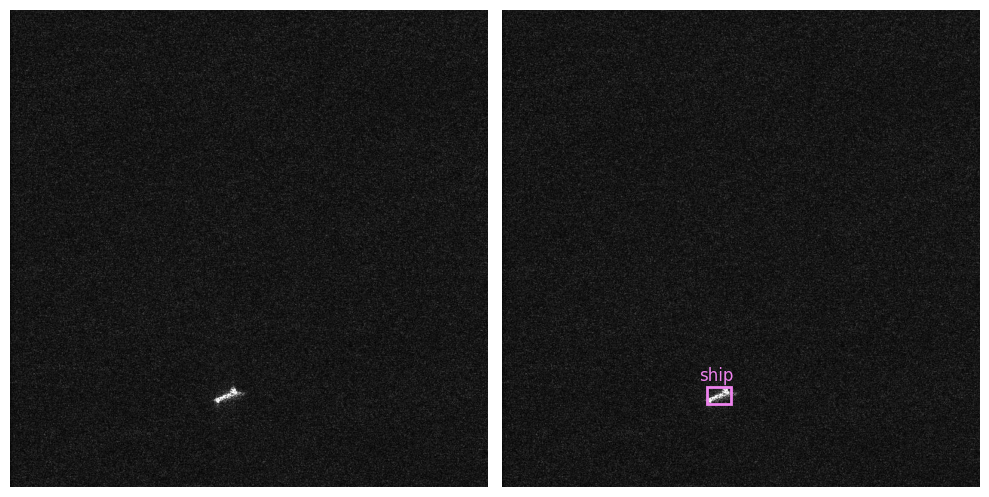

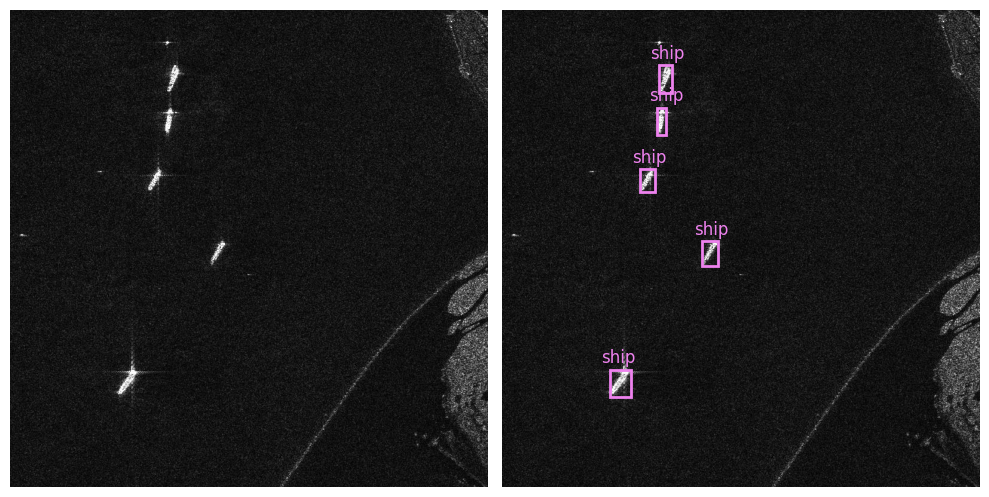

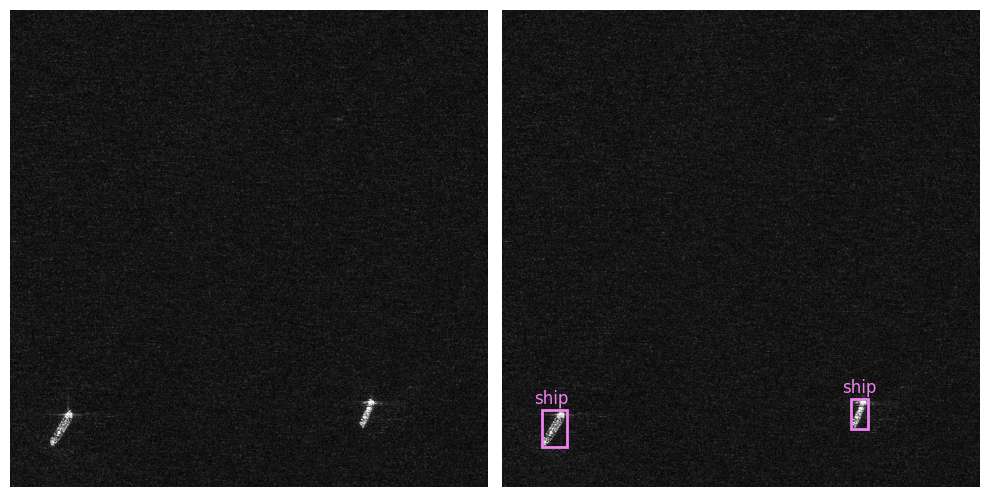

In [ ]:
fig1 = dataset.show_image(5)
fig2 = dataset.show_image(10)
fig3 = dataset.show_image(100);

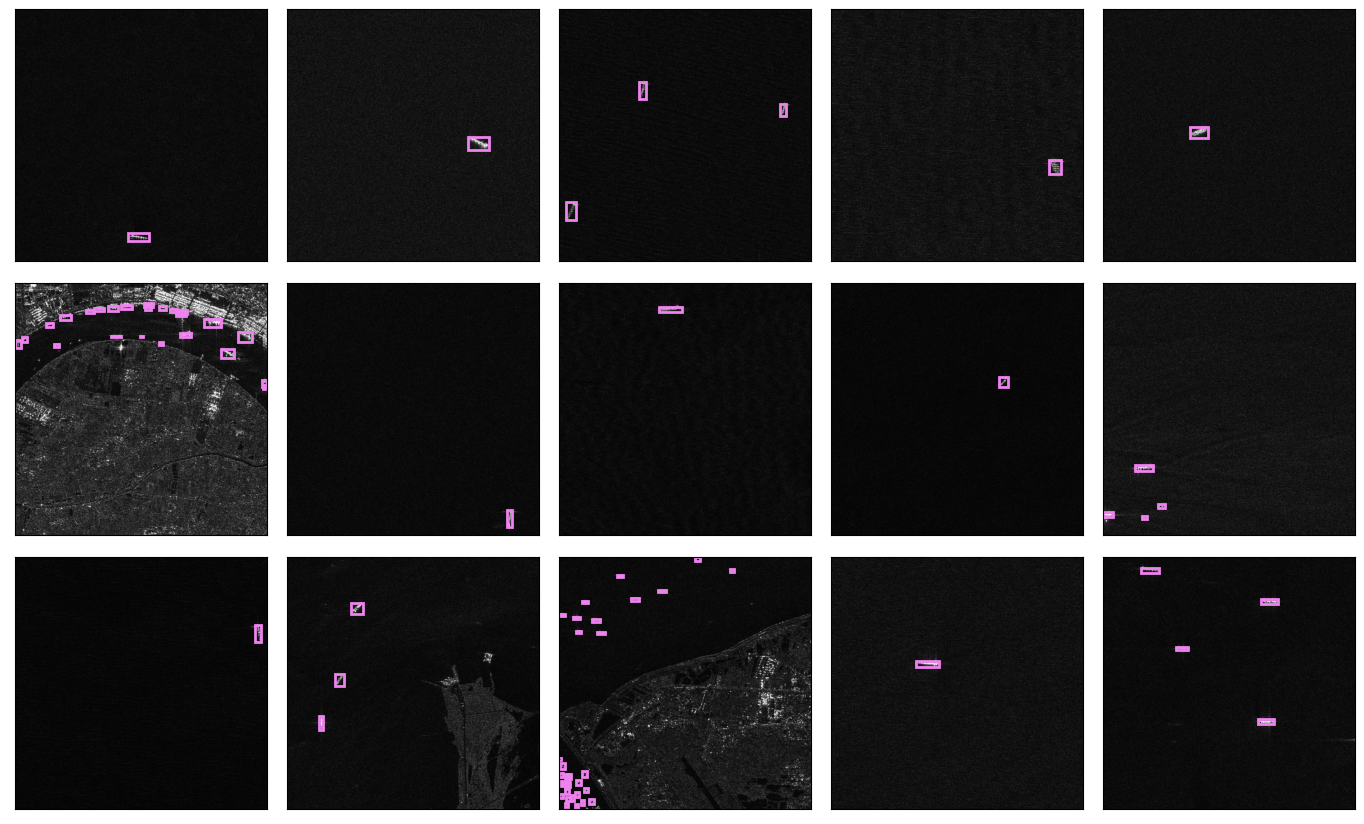

In [ ]:
fig = dataset.show_batch(15);

In [11]:
dataset.data_distribution_table()

,Label,Count
0,ship,16951


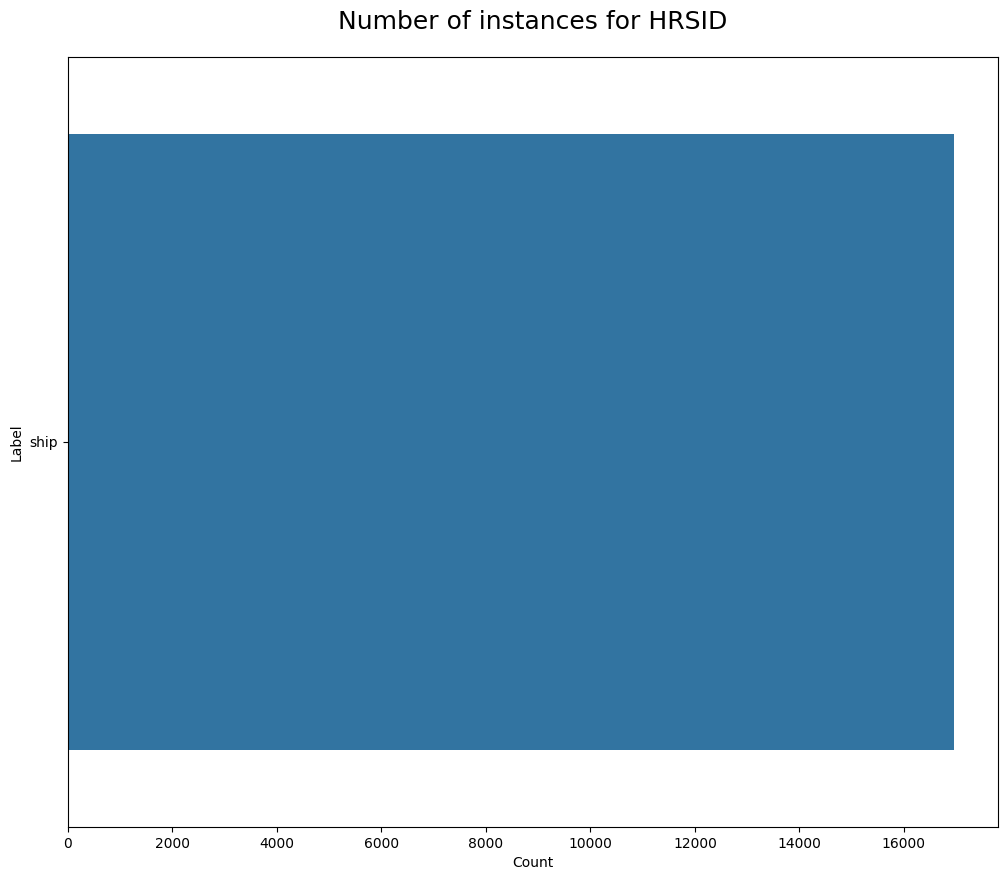

In [ ]:
fig = dataset.data_distribution_barchart();

## Load train data

In [25]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/HRSID/JPEGImages",
    "annotation_dir": "/home/dragik/data/FAIR_EO/HRSID/annotations/train2017.json",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = HRSIDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 3639


## Create the model

In [26]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/hrsid"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [27]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-07-07 09:56:59,033 INFO Starting training.
training: 100%|██████████| 455/455 [02:31<00:00,  3.00it/s]
2025-07-07 09:59:30,990 INFO epoch: 1, time: 151, loss:  0.18517
testing on train set: 100%|██████████| 455/455 [01:18<00:00,  5.79it/s]
2025-07-07 10:01:01,989 INFO map:0.5663525462150574, map_50:0.8120747208595276, map_75:0.6729880571365356, map_small:0.558976948261261, map_medium:0.6734556555747986, map_large:0.40898367762565613, mar_1:0.26249998807907104, mar_10:0.5541545748710632, mar_100:0.6302545666694641, mar_small:0.6192573308944702, mar_medium:0.74979168176651, mar_large:0.5346938967704773, map_per_class:0.5663525462150574, mar_100_per_class:0.6302545666694641, classes:1.0
training: 100%|██████████| 455/455 [02:30<00:00,  3.01it/s]
2025-07-07 10:03:32,947 INFO epoch: 2, time: 151, loss:  0.13076
testing on train set: 100%|██████████| 455/455 [01:18<00:00,  5.78it/s]
2025-07-07 10:05:00,707 INFO map:0.6406710743904114, map_50:0.8826751112937927, map_75:0.7625478506088257

0.06161426507217047

## Predictions

2025-07-08 06:58:13,577 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/hrsid/checkpoint.pth.tar
2025-07-08 06:58:14,255 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/hrsid/checkpoint.pth.tar at epoch 11


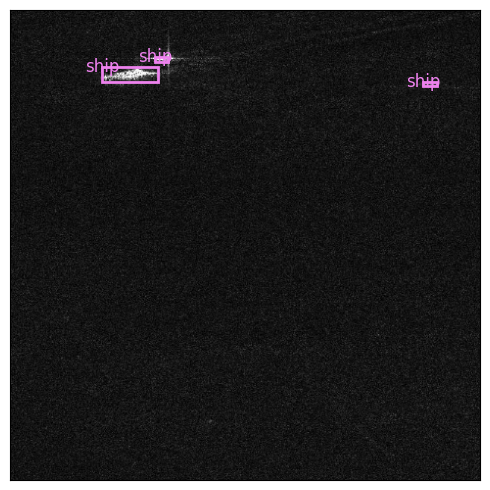

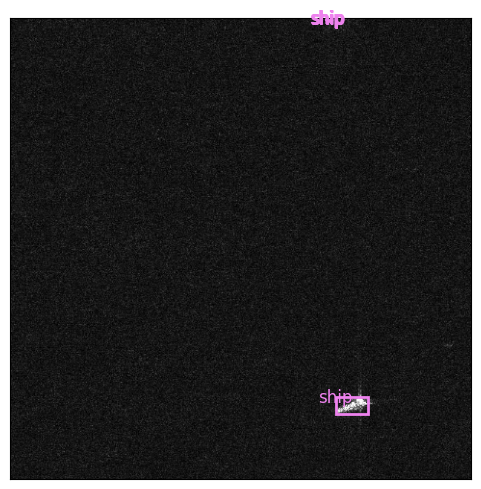

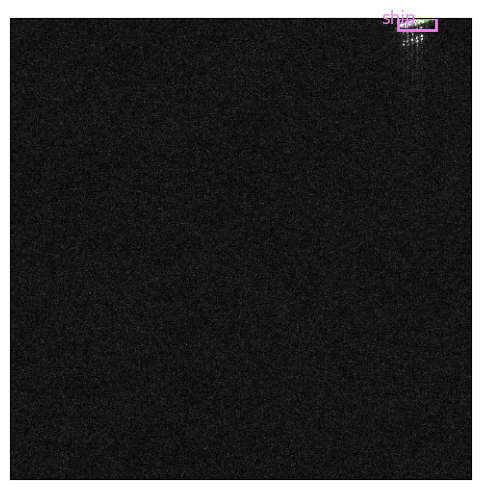

In [6]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/experiments/hrsid/checkpoint.pth.tar"
labels = ["no-data","ship"]
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/HRSID/JPEGImages/P0001_0_800_10190_10990.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/HRSID/JPEGImages/P0001_3000_3800_1800_2600.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/HRSID/JPEGImages/P0001_4800_5600_1800_2600.jpg')
fig = model.detect_objects(image, labels, transform)